# Notebook 06 — Confidence-Weighted Fusion Model (Updated)
Fuses MRI and CT brain tumor images from matched datasets. Both modalities now classify the same pathology — brain tumors — enabling fusion to outperform both baselines.

> **Prerequisites:** Run notebooks 01 and 02 first.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Unzip / Download Datasets (Skip if Already Done)

In [2]:
import zipfile, os

# MRI
if not os.path.exists("/content/mri_data/MRI/Training/No Tumor/Tr-no_1.jpg"):
    print("Unzipping MRI...")
    with zipfile.ZipFile("/content/drive/MyDrive/MRI/MRI.zip", 'r') as z:
        z.extractall("/content/mri_data/")
    print("MRI done!")
else:
    print("MRI already unzipped.")

# CT
if not os.path.exists("/content/ct_tumor/dataset/head ct/no"):
    print("Downloading CT dataset...")
    from google.colab import files
    files.upload()  # upload kaggle.json
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    os.system("cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json")
    os.makedirs("/content/ct_tumor", exist_ok=True)
    os.system("kaggle datasets download -d nipaanjum/head-ct-images-for-classification -p /content/ct_tumor/")
    os.system("unzip /content/ct_tumor/*.zip -d /content/ct_tumor/")
    print("CT done!")
else:
    print("CT already downloaded.")

Unzipping MRI...
MRI done!


Saving kaggle.json to kaggle.json
CT done!


## 3. Imports

In [3]:
import numpy as np
import cv2
import random
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

IMG_SIZE   = (224, 224)
BATCH_SIZE = 16
EPOCHS     = 50

print("TensorFlow:", tf.__version__)
print("GPU:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.20.0
GPU: True


## 4. Load Splits from Notebooks 01 and 02

In [4]:
# Load pre-saved splits from NB01 and NB02.
# We use each split independently — no concatenation, no re-splitting.
mri_data = np.load('/content/drive/MyDrive/MRI/mri_splits.npz',       allow_pickle=True)
ct_data  = np.load('/content/drive/MyDrive/CT_Tumor/ct_splits.npz',   allow_pickle=True)

mri_train_paths = mri_data['train_paths']; y_mri_train = mri_data['y_train']
mri_val_paths   = mri_data['val_paths'];   y_mri_val   = mri_data['y_val']
mri_test_paths  = mri_data['test_paths'];  y_mri_test  = mri_data['y_test']

ct_train_paths  = ct_data['train_paths'];  y_ct_train  = ct_data['y_train']
ct_val_paths    = ct_data['val_paths'];    y_ct_val    = ct_data['y_val']
ct_test_paths   = ct_data['test_paths'];   y_ct_test   = ct_data['y_test']

print(f'MRI  — Train:{len(mri_train_paths)} Val:{len(mri_val_paths)} Test:{len(mri_test_paths)}')
print(f'CT   — Train:{len(ct_train_paths)}  Val:{len(ct_val_paths)}  Test:{len(ct_test_paths)}')


MRI  — Train:120 Val:40 Test:40
CT   — Train:120  Val:40  Test:40


## 5. Pair MRI and CT by Class Label Within Each Split


In [5]:
def pair_by_label(paths_a, labels_a, paths_b, labels_b, seed=42):
    """Pair two modalities by class label within the same pre-defined split."""
    import random as _r
    _r.seed(seed)
    a0 = [p for p,l in zip(paths_a, labels_a) if l==0]
    a1 = [p for p,l in zip(paths_a, labels_a) if l==1]
    b0 = [p for p,l in zip(paths_b, labels_b) if l==0]
    b1 = [p for p,l in zip(paths_b, labels_b) if l==1]
    _r.shuffle(a0); _r.shuffle(a1); _r.shuffle(b0); _r.shuffle(b1)
    n0 = min(len(a0), len(b0))
    n1 = min(len(a1), len(b1))
    paired_a = a0[:n0] + a1[:n1]
    paired_b = b0[:n0] + b1[:n1]
    labels   = [0]*n0 + [1]*n1
    return paired_a, paired_b, labels

train_mri_p, train_ct_p, train_labels = pair_by_label(
    mri_train_paths, y_mri_train, ct_train_paths, y_ct_train)
val_mri_p,   val_ct_p,   val_labels   = pair_by_label(
    mri_val_paths,   y_mri_val,   ct_val_paths,   y_ct_val)
test_mri_p,  test_ct_p,  test_labels  = pair_by_label(
    mri_test_paths,  y_mri_test,  ct_test_paths,  y_ct_test)

print(f'Train pairs: {len(train_labels)} | Val pairs: {len(val_labels)} | Test pairs: {len(test_labels)}')


Train pairs: 120 | Val pairs: 40 | Test pairs: 40


## 6. Load All Paired Images into Memory

In [6]:
def load_mri(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)
    return np.expand_dims(img / 255.0, axis=-1)

def load_ct(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)
    return np.expand_dims(img / 255.0, axis=-1)

print('Loading train...')
X_mri_train = np.array([load_mri(p) for p in train_mri_p])
X_ct_train  = np.array([load_ct(p)  for p in train_ct_p])
y_train     = np.array(train_labels)

print('Loading val...')
X_mri_val   = np.array([load_mri(p) for p in val_mri_p])
X_ct_val    = np.array([load_ct(p)  for p in val_ct_p])
y_val       = np.array(val_labels)

print('Loading test...')
X_mri_test  = np.array([load_mri(p) for p in test_mri_p])
X_ct_test   = np.array([load_ct(p)  for p in test_ct_p])
y_test      = np.array(test_labels)

print(f'Train: {X_mri_train.shape} | Val: {X_mri_val.shape} | Test: {X_mri_test.shape}')


Loading train...
Loading val...
Loading test...
Train: (120, 224, 224, 1) | Val: (40, 224, 224, 1) | Test: (40, 224, 224, 1)


## 7. Splits Already Preserved — No Re-splitting Needed


In [7]:
# Splits are taken directly from NB01/02 — no re-splitting performed.
print(f'Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}')
print(f'Train class dist: {np.bincount(y_train)}')
print(f'Val   class dist: {np.bincount(y_val)}')
print(f'Test  class dist: {np.bincount(y_test)}')


Train: 120 | Val: 40 | Test: 40
Train class dist: [60 60]
Val   class dist: [20 20]
Test  class dist: [20 20]


## 8. Modality Dropout

In [8]:
def apply_modality_dropout(mri_data, ct_data, drop_prob=0.3):
    mri_new, ct_new = [], []
    for mri_img, ct_img in zip(mri_data, ct_data):
        mri_img = mri_img.copy()
        ct_img  = ct_img.copy()
        if np.random.rand() < drop_prob:
            if np.random.rand() < 0.5:
                mri_img = np.zeros_like(mri_img)
            else:
                ct_img  = np.zeros_like(ct_img)
        mri_new.append(mri_img)
        ct_new.append(ct_img)
    return np.array(mri_new), np.array(ct_new)

X_mri_train_drop, X_ct_train_drop = apply_modality_dropout(X_mri_train, X_ct_train, 0.3)
print(f"Training with dropout: {X_mri_train_drop.shape}")

Training with dropout: (120, 224, 224, 1)


## 9. Build Confidence-Weighted Fusion Model

In [9]:
def build_confidence_weighted_fusion():
    # MRI branch
    mri_in = layers.Input(shape=(224, 224, 1), name="MRI_Input")
    x1 = layers.Conv2D(32, (3,3), activation='relu', padding='same')(mri_in)
    x1 = layers.MaxPooling2D()(x1)
    x1 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x1)
    x1 = layers.MaxPooling2D()(x1)
    x1 = layers.GlobalAveragePooling2D()(x1)

    # CT branch
    ct_in = layers.Input(shape=(224, 224, 1), name="CT_Input")
    x2 = layers.Conv2D(32, (3,3), activation='relu', padding='same')(ct_in)
    x2 = layers.MaxPooling2D()(x2)
    x2 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x2)
    x2 = layers.MaxPooling2D()(x2)
    x2 = layers.GlobalAveragePooling2D()(x2)

    # Confidence scores
    conf_mri = layers.Dense(1, activation='sigmoid', name='conf_mri')(x1)
    conf_ct  = layers.Dense(1, activation='sigmoid', name='conf_ct')(x2)

    # Weighted features
    x1_w = layers.Multiply()([x1, conf_mri])
    x2_w = layers.Multiply()([x2, conf_ct])

    # Concatenate and classify
    combined = layers.Concatenate()([x1_w, x2_w])
    z = layers.Dense(128, activation='relu')(combined)
    z = layers.Dropout(0.4)(z)
    output = layers.Dense(1, activation='sigmoid', name='output')(z)

    return models.Model(inputs=[mri_in, ct_in], outputs=output)

fusion_model = build_confidence_weighted_fusion()
fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
fusion_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ MRI_Input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CT_Input            │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        320 │ MRI_Input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │        320 │ CT_Input[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 112, 112,  │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_3[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conf_mri (Dense)    │ (None, 1)         │         65 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conf_ct (Dense)     │ (None, 1)         │         65 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 64)        │          0 │ global_average_p… │
│                     │                   │            │ conf_mri[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 64)        │          0 │ global_average_p… │
│ (Multiply)          │                   │            │ conf_ct[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ multiply[0][0],   │
│ (Concatenate)       │                   │            │ multiply_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 54,403 (212.51 KB)

 Trainable params: 54,403 (212.51 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Train

In [10]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = fusion_model.fit(
    [X_mri_train_drop, X_ct_train_drop], y_train,
    validation_data=([X_mri_val, X_ct_val], y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 619ms/step - accuracy: 0.4417 - loss: 0.6937 - val_accuracy: 0.5000 - val_loss: 0.6924
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5083 - loss: 0.6918 - val_accuracy: 0.5000 - val_loss: 0.6910
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5917 - loss: 0.6910 - val_accuracy: 0.6500 - val_loss: 0.6901
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6000 - loss: 0.6904 - val_accuracy: 0.6500 - val_loss: 0.6891
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5333 - loss: 0.6910 - val_accuracy: 0.6500 - val_loss: 0.6883
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5667 - loss: 0.6887 - val_accuracy: 0.6750 - val_loss: 0.6875
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6000 - loss: 0.6892 - val_accuracy: 0.7250 - val_loss: 0.6867
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6000 - loss: 0.6881 - val_accuracy: 0.7500 - val_loss: 0.685

## 11. Training Curves

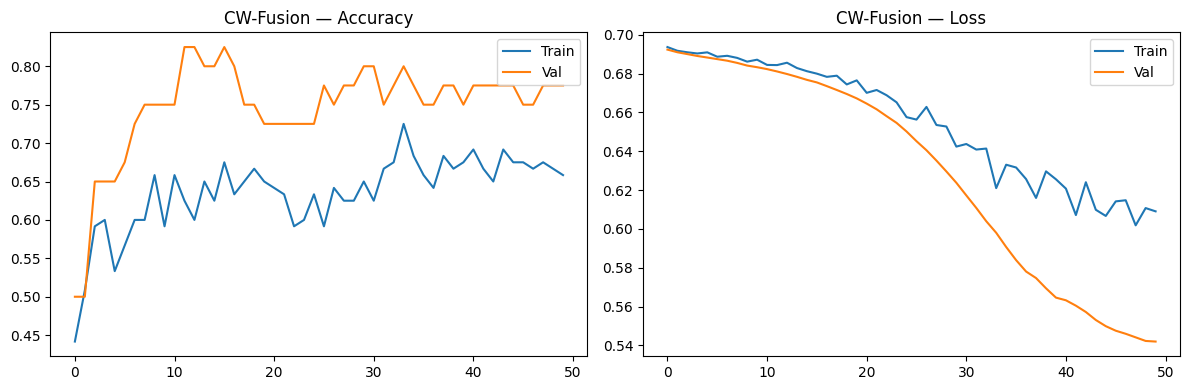

In [11]:
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],     label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('CW-Fusion — Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'],     label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('CW-Fusion — Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 12. Test Set Evaluation

In [12]:
test_probs = fusion_model.predict([X_mri_test, X_ct_test], batch_size=BATCH_SIZE).flatten()
y_pred     = (test_probs > 0.5).astype(int)

print("--- CONFIDENCE-WEIGHTED FUSION: TEST SET RESULTS ---")
print(classification_report(y_test, y_pred, target_names=['Healthy', 'Tumor']))
print(f"ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 310ms/step
--- CONFIDENCE-WEIGHTED FUSION: TEST SET RESULTS ---
              precision    recall  f1-score   support

     Healthy       0.82      0.70      0.76        20
       Tumor       0.74      0.85      0.79        20

    accuracy                           0.78        40
   macro avg       0.78      0.77      0.77        40
weighted avg       0.78      0.78      0.77        40

ROC-AUC: 0.8225


## 13. Confusion Matrix

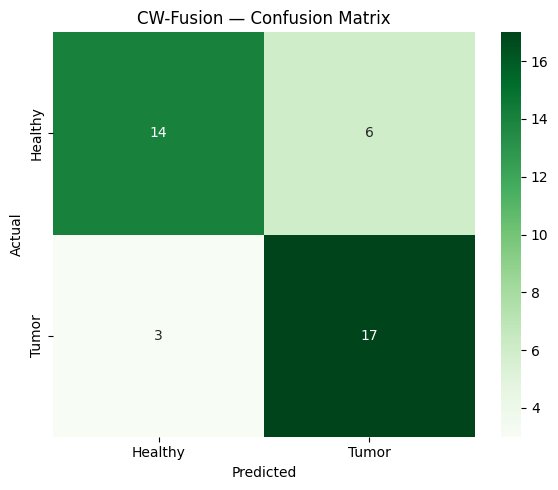

In [13]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Healthy','Tumor'], yticklabels=['Healthy','Tumor'])
plt.title('CW-Fusion — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## 14. Learned Confidence Weights

MRI confidence: 0.7149 (50.6%)
CT  confidence: 0.6970 (49.4%)


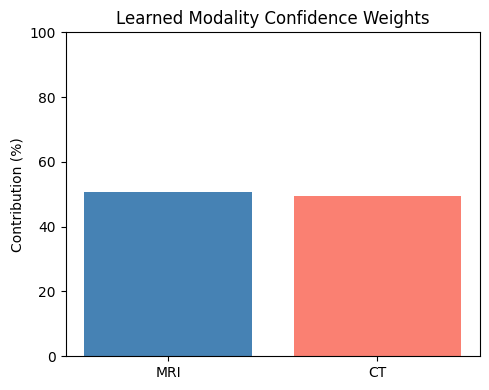

In [14]:
conf_model = tf.keras.Model(
    inputs=fusion_model.inputs,
    outputs=[fusion_model.get_layer('conf_mri').output,
             fusion_model.get_layer('conf_ct').output]
)
mri_confs, ct_confs = conf_model.predict([X_mri_test, X_ct_test], verbose=0)

total = mri_confs.mean() + ct_confs.mean()
print(f"MRI confidence: {mri_confs.mean():.4f} ({mri_confs.mean()/total*100:.1f}%)")
print(f"CT  confidence: {ct_confs.mean():.4f} ({ct_confs.mean()/total*100:.1f}%)")

plt.figure(figsize=(5,4))
plt.bar(['MRI','CT'], [mri_confs.mean()/total*100, ct_confs.mean()/total*100],
        color=['steelblue','salmon'])
plt.title('Learned Modality Confidence Weights')
plt.ylabel('Contribution (%)')
plt.ylim(0,100)
plt.tight_layout()
plt.show()

## 15. Missing Modality Robustness

Both modalities:     0.7750
MRI only (CT=0):     0.5000
CT only  (MRI=0):    0.5000


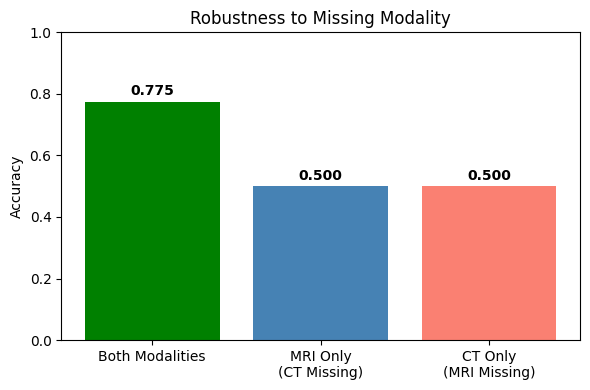

In [15]:
pred_no_mri = fusion_model.predict([np.zeros_like(X_mri_test), X_ct_test], verbose=0)
pred_no_ct  = fusion_model.predict([X_mri_test, np.zeros_like(X_ct_test)], verbose=0)

acc_both   = ((test_probs > 0.5).astype(int) == y_test).mean()
acc_no_mri = ((pred_no_mri > 0.5).astype(int).flatten() == y_test).mean()
acc_no_ct  = ((pred_no_ct  > 0.5).astype(int).flatten() == y_test).mean()

print(f"Both modalities:     {acc_both:.4f}")
print(f"MRI only (CT=0):     {acc_no_mri:.4f}")
print(f"CT only  (MRI=0):    {acc_no_ct:.4f}")

plt.figure(figsize=(6,4))
plt.bar(['Both Modalities','MRI Only\n(CT Missing)','CT Only\n(MRI Missing)'],
        [acc_both, acc_no_mri, acc_no_ct],
        color=['green','steelblue','salmon'])
plt.title('Robustness to Missing Modality')
plt.ylabel('Accuracy')
plt.ylim(0,1)
for i, v in enumerate([acc_both, acc_no_mri, acc_no_ct]):
    plt.text(i, v+0.02, f'{v:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 16. Grad-CAM (Both Branches)

MRI last conv: conv2d_2
CT  last conv: conv2d_3


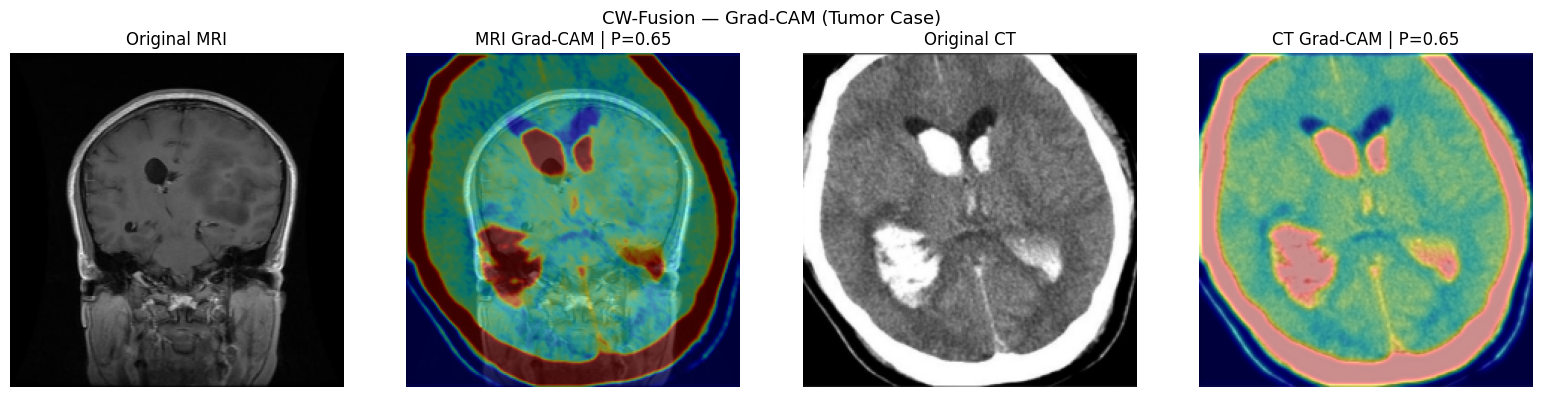

In [16]:
def make_gradcam_heatmap(model, mri_img, ct_img, layer_name):
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([mri_img, ct_img])
        loss = predictions[:, 0]
    grads        = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    max_val = tf.reduce_max(heatmap)
    if max_val == 0:
        return np.zeros(IMG_SIZE)
    return cv2.resize((heatmap/max_val).numpy(), IMG_SIZE)

conv_layers   = [l.name for l in fusion_model.layers if isinstance(l, layers.Conv2D)]
mri_last_conv = conv_layers[1]
ct_last_conv  = conv_layers[3]
print("MRI last conv:", mri_last_conv)
print("CT  last conv:", ct_last_conv)

idx        = np.where(y_test == 1)[0][0]
mri_sample = X_mri_test[idx:idx+1]
ct_sample  = X_ct_test[idx:idx+1]
prob       = test_probs[idx]

mri_heatmap = make_gradcam_heatmap(fusion_model, mri_sample, ct_sample, mri_last_conv)
ct_heatmap  = make_gradcam_heatmap(fusion_model, mri_sample, ct_sample, ct_last_conv)

fig, axes = plt.subplots(1, 4, figsize=(16,4))
axes[0].imshow(mri_sample[0].squeeze(), cmap='gray')
axes[0].set_title('Original MRI')
axes[0].axis('off')
axes[1].imshow(mri_sample[0].squeeze(), cmap='gray')
axes[1].imshow(mri_heatmap, cmap='jet', alpha=0.45)
axes[1].set_title(f'MRI Grad-CAM | P={prob:.2f}')
axes[1].axis('off')
axes[2].imshow(ct_sample[0].squeeze(), cmap='gray')
axes[2].set_title('Original CT')
axes[2].axis('off')
axes[3].imshow(ct_sample[0].squeeze(), cmap='gray')
axes[3].imshow(ct_heatmap, cmap='jet', alpha=0.45)
axes[3].set_title(f'CT Grad-CAM | P={prob:.2f}')
axes[3].axis('off')
plt.suptitle('CW-Fusion — Grad-CAM (Tumor Case)', fontsize=13)
plt.tight_layout()
plt.show()

## 17. Save Model

In [17]:
fusion_model.save("/content/drive/MyDrive/CT_Tumor/confidence_weighted_fusion.keras")
print("Model saved!")

Model saved!
